In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec
import matplotlib.colors as colors
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib import cm
from matplotlib.patches import Patch

import os
import scanpy as sc

import seaborn as sns
import snapatac2 as snap

snap.__version__



plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6

/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Data

In [2]:
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
Union_cell_subdir = os.path.join(entropy_dir, '_cell_calling_comparison')

Union_cell_rna_cluster_file = os.path.join(Union_cell_subdir,  'Union_cell_3set_with_RNA_cluster.tsv')
Union_cell_rna_cluster_df = pd.read_csv(Union_cell_rna_cluster_file, sep='\t', index_col=0)
Union_cell_rna_cluster_df['atac_barcode'] = Union_cell_rna_cluster_df.index.map(lambda x: x + '-1') 

union_cell_noDebrisDoublet_cluster_file = os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'snap_cluster_unioncells_noDebrisDoublets.tsv')

union_cell_noDebrisDoublet_cluster_df = pd.read_csv(union_cell_noDebrisDoublet_cluster_file, sep='\t', index_col=0)

data = sc.read_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_all_unioncells.h5ad'))

data.obs['leiden_RNA_scVI'] = data.obs.index.map(Union_cell_rna_cluster_df['leiden_RNA_scVI']).fillna('no_rna_info')
data.obs['filtered_leiden'] = data.obs.index.map(union_cell_noDebrisDoublet_cluster_df['filtered_leiden']).fillna('Debris_or_doublet')

data.obs['debris_doublets_flag'] = data.obs.apply(lambda row: 
    'debrisNdoublet' if row['DNA_debris'] == 'YES' and row['amulet_doublet_atac'] == True \
        else ('doublets' if row['amulet_doublet_atac'] == True \
            else ('Debris' if row['DNA_debris'] == 'YES' else 'clean')), axis=1)


In [3]:
data

AnnData object with n_obs × n_vars = 2384 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden', 'leiden_RNA_scVI', 'filtered_leiden', 'debris_doublets_flag'
    var: 'count', 'selected'
    uns: 'DNA_debris_colors', 'TSS_profile', '_3set_identified_by_atac_colors', 'amulet_doublet_atac_colors', 'frac_overlap_TSS', 'leiden_colors', 'library_tsse', 'reference_sequences', 'rna_pass_CR_colors', 'spectral_eigenvalue'
    obsm: 'X_spectral', 'X_umap', 'fragment_paired'
    obsp: 'distances'

# Identified cell quality

In [4]:
# cluster 0 mainly has unqualified RNA
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet', 0.0])]['atac_pass_CR'].value_counts()

atac_pass_CR
True     1830
False     164
Name: count, dtype: int64

In [5]:
# cluster 0 mainly has unqualified RNA
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet', 0.0])]['atac_pass_entropy'].value_counts()

atac_pass_entropy
True     1934
False      60
Name: count, dtype: int64

In [6]:
# cluster 0 mainly has unqualified RNA
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet', 0.0])]['atac_pass_archr_TSS'].value_counts()

atac_pass_archr_TSS
True     1857
False     137
Name: count, dtype: int64

In [7]:
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet'])].groupby(['atac_pass_CR', 'rna_pass_CR']).size().unstack(fill_value=0)

rna_pass_CR,False,True
atac_pass_CR,,
False,272,153
True,58,1803


In [8]:
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet'])].groupby(['atac_pass_entropy', 'rna_pass_CR']).size().unstack(fill_value=0)

rna_pass_CR,False,True
atac_pass_entropy,,
False,203,58
True,127,1898


In [9]:
data.obs.loc[~data.obs['filtered_leiden'].isin(['Debris_or_doublet'])].groupby(['atac_pass_archr_TSS', 'rna_pass_CR']).size().unstack(fill_value=0)

rna_pass_CR,False,True
atac_pass_archr_TSS,,
False,94,125
True,236,1831


## Vis above 

In [10]:
# 1st originally the number of nuclei identified by each method 
filtering_methods = ['atac_pass_entropy', 'atac_pass_CR', 'atac_pass_archr_TSS']
filtering_methods_names = ['SADE droplets', 'CR droplets', 'TSSe droplets']
filtering_methods_names_map = dict(zip(filtering_methods, filtering_methods_names))
Nnuclei_per_method = pd.DataFrame({
    #
    'Initially permitted': [data.obs[method].sum() for method in filtering_methods]
}, index=filtering_methods_names)


# 2nd the number of post-QC nuclei that removes DNA-debris, doublets, and inefficient ATAC features for downstream analysis 
data_postQC = data.obs[ ~(data.obs['filtered_leiden'].isin(['Debris_or_doublet', 0.0 ]))].copy()
Nuclei_per_method_postATACQC = pd.DataFrame({
    # Clean meaning no DNA-debris, no doublets, and good ATAC features, which are the nuclei used for downstream analysis
    'Clean': [ 
        data_postQC[method].sum() for method in filtering_methods
    ]
}, index=filtering_methods_names)


# 3rd the number of nuclei passed ATAC QC with valid RNA data
data_with_good_RNA = data_postQC[data_postQC['rna_pass_CR'] == True].copy()
Nuclei_per_method_goodRNA = pd.DataFrame({
    'With qualified RNA': [
        data_with_good_RNA[method].sum() for method in filtering_methods
    ]
}, index=filtering_methods_names)


combined = pd.concat([Nnuclei_per_method,  Nuclei_per_method_postATACQC, Nuclei_per_method_goodRNA], axis=1)
# combined = combined.set_index('method')

In [11]:
combined

,Initially permitted,Clean,With qualified RNA
SADE droplets,2101,1934,1894
CR droplets,1959,1830,1797
TSSe droplets,2132,1857,1826


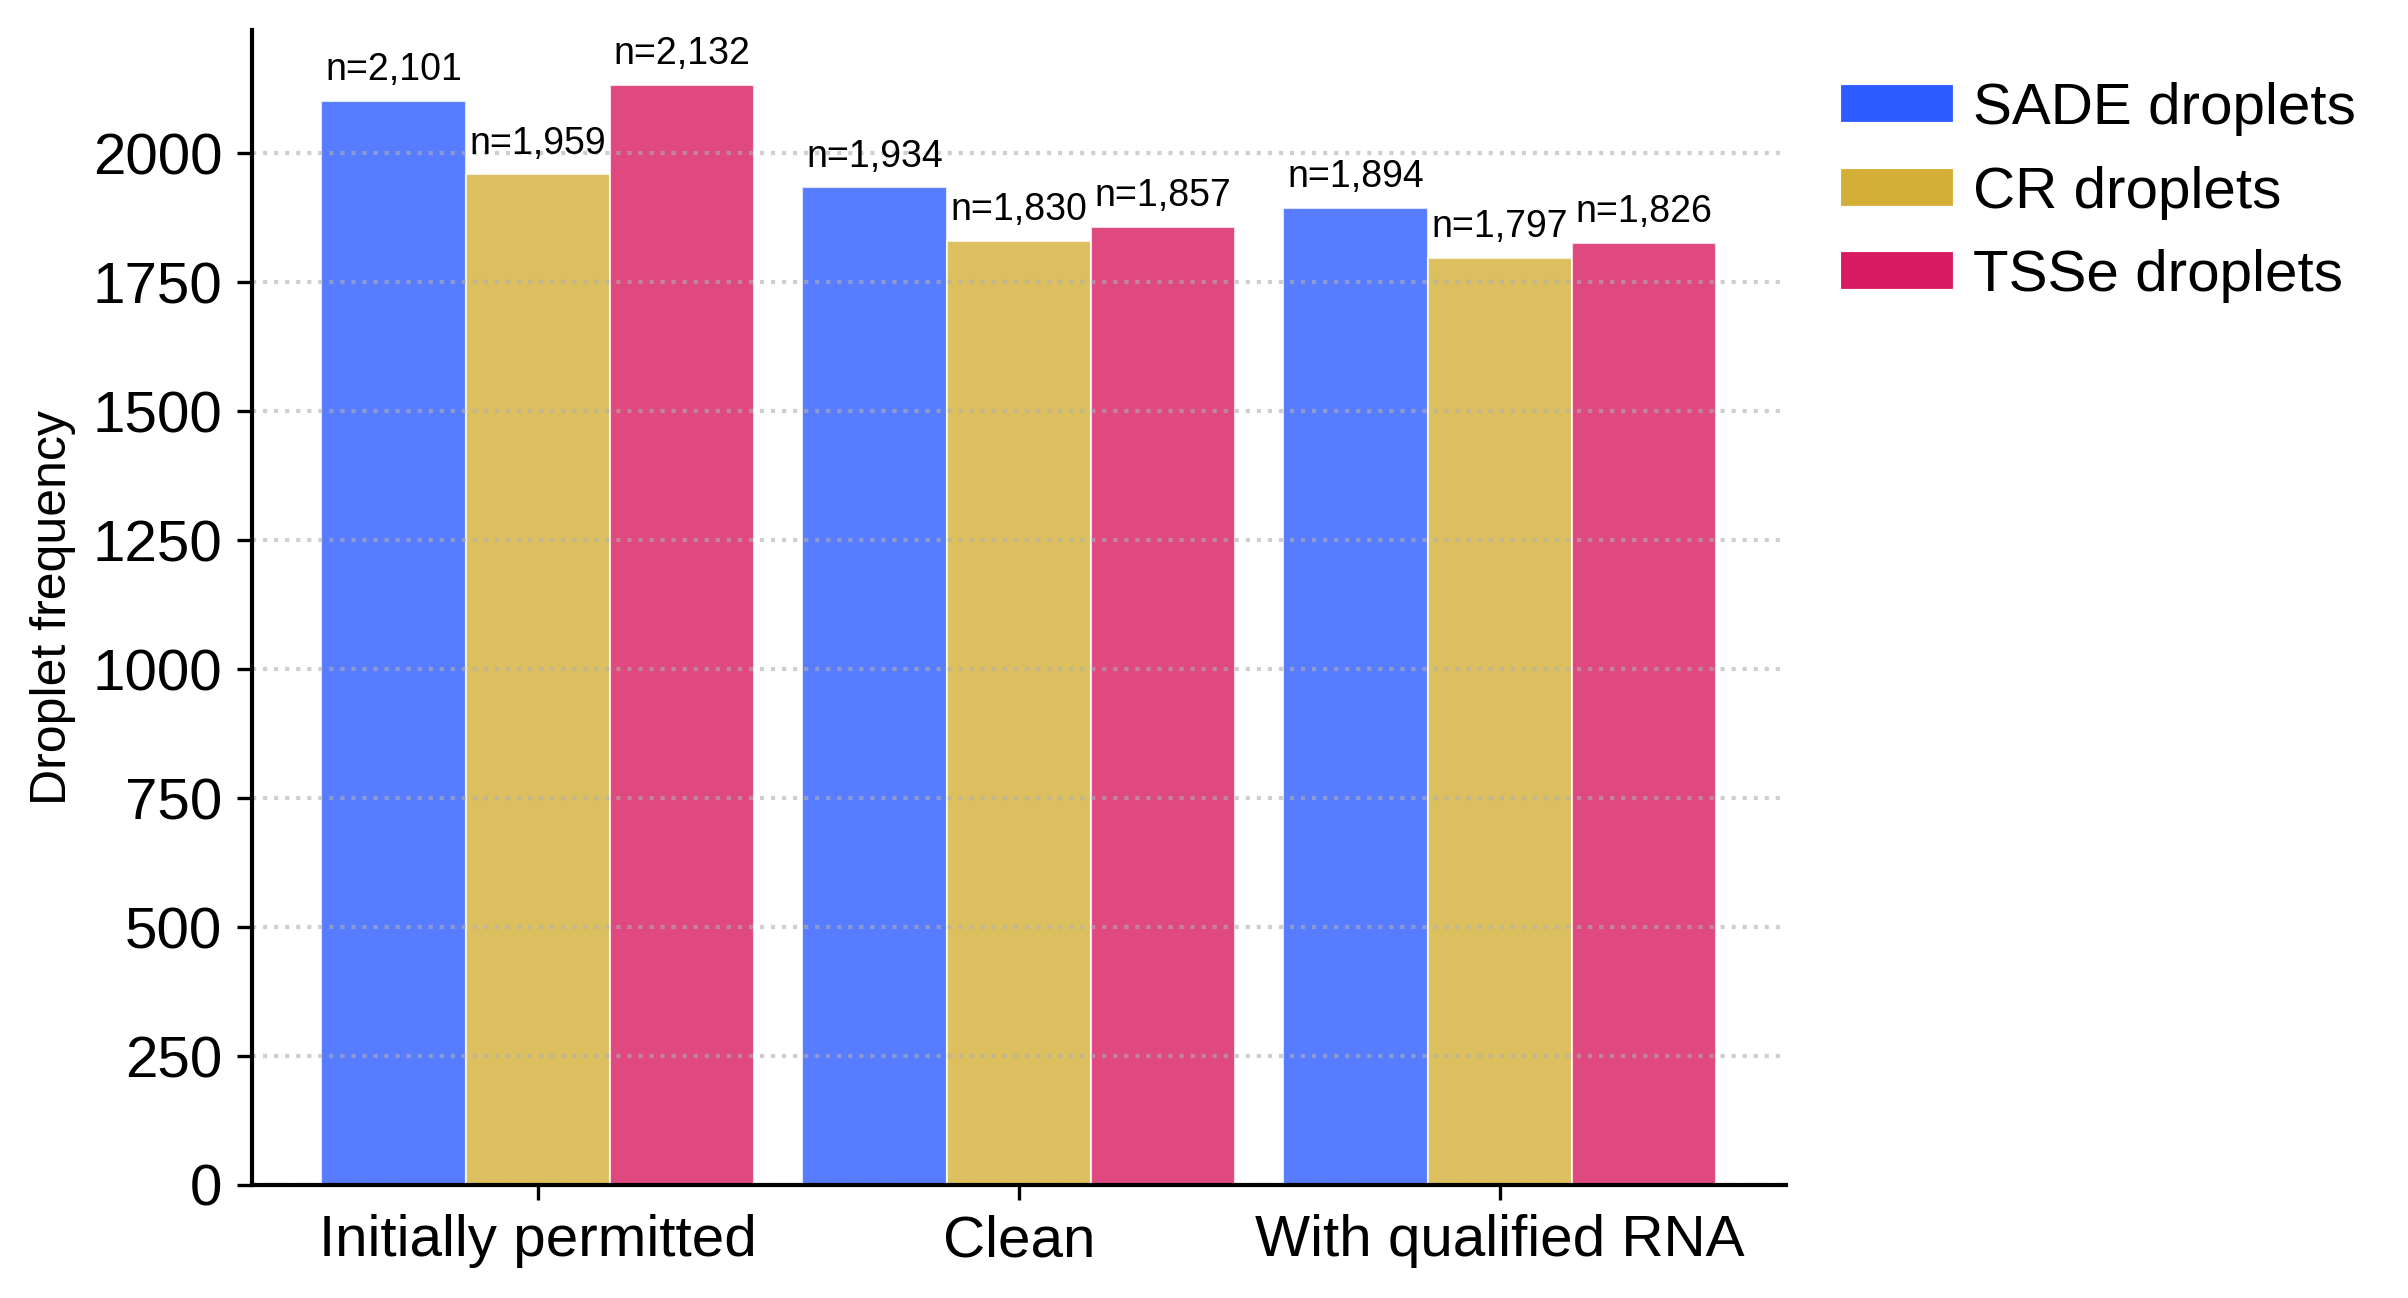

In [12]:
fig, ax = plt.subplots(figsize=(6.6, 5))

# SADE, CR, TSS
methods = combined.index
colors = ['#2E5BFF', "#D4AF37", '#D81B60',]
n_stages = combined.shape[1]
x_positions = np.arange(len(methods))
width = 0.3

for i, stage in enumerate(combined.columns):
    pos = x_positions[i] + (np.arange(n_stages) - (n_stages-1)/2) * width
    
    bars = ax.bar(pos, combined[stage], width, 
                  color=colors, 
                  edgecolor='white', 
                  linewidth=0.5,
                  alpha=0.8)
    
    ax.bar_label(bars, 
                labels=[f'n={int(bar.get_height()):,}' for bar in bars], 
                padding=3, 
                fontsize=9, 
                rotation=0)
# 4. Formatting
ax.set_ylabel('Droplet frequency', fontsize=12)
# ax.set_title('Valid nuclei at each stage', fontsize=14, pad=15)

# Set ticks to the middle of the 3-bar groups
ax.set_xticks(x_positions)
ax.set_xticklabels(combined.columns)

# Custom Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=c, edgecolor='white', label=method) for c, method in zip(colors, methods)
]
ax.legend(handles=legend_elements,  frameon=False, bbox_to_anchor=(1.0, 1), loc='upper left', handletextpad=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle=':', alpha=0.6)

fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p2.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p2.pdf'))